# Etap 1 — Eksploracja danych

Zanim napiszemy pipeline, musimy wiedziec, **jakie pulapki siedza w danych**.
Pipeline pisany "na slepo" dziala do pierwszej zmiany czasu, pierwszej dziury
w danych albo pierwszej korekty publikacji.

Pytania na ten notebook:
1. Jak dziala API PSE (filtry, stronicowanie)?
2. Jak wyglada czas w danych (strefy, zmiana czasu)?
3. Czy dane sa kompletne?
4. Czy prognozy PSE nadaja sie na uczciwy benchmark?
5. Jakie dane pogodowe mozemy uzyc bez "podgladania przyszlosci"?

In [1]:
import httpx
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

PSE_API = "https://api.raporty.pse.pl/api"

## 1. API PSE — stronicowanie

API zwraca maksymalnie **100 wierszy na strone**. Jesli danych jest wiecej, w odpowiedzi
jest pole `nextLink` z adresem kolejnej strony. Trzeba za nim isc w petli, dopoki
`nextLink` nie zniknie. To czesty wzorzec w API (tzw. paginacja kursorowa).

Filtry podajemy w skladni OData: `$filter=business_date ge '2026-03-01'`.

In [2]:
def pobierz_pse(raport: str, od: str, do: str) -> pd.DataFrame:
    """Pobiera raport PSE dla dob handlowych [od, do], przechodzac po wszystkich stronach."""
    url = f"{PSE_API}/{raport}"
    params = {"$filter": f"business_date ge '{od}' and business_date le '{do}'"}
    wiersze = []
    with httpx.Client(timeout=60) as klient:
        while url:
            odp = klient.get(url, params=params)
            odp.raise_for_status()
            dane = odp.json()
            wiersze.extend(dane["value"])
            url = dane.get("nextLink")
            params = None  # nextLink ma juz wszystkie parametry w sobie
    return pd.DataFrame(wiersze)


# Okres z wiosenna zmiana czasu (29.03.2026) i duza generacja z PV
wykonanie = pobierz_pse("his-wlk-cal", "2026-03-01", "2026-04-30")
print(wykonanie.shape)
wykonanie.head()

(5852, 24)


,jg,pv,wi,jga,jgm,jgo,jgm1,jgm2,jgw1,jgw2,jgz1,jgz2,jgz3,dtime,jnwrb,swm_p,demand,period,swm_np,dtime_utc,period_utc,business_date,publication_ts,publication_ts_utc
0,7351.102,0.0,3340.221,None,-17.735,None,0.0,8.44,7230.168,112.494,None,NaN,None,2026-03-01 00:15:00,7375.439,12.251,14762.815,00:00 - 00:15,41.358,2026-02-28 23:15:00,23:00 - 23:15,2026-03-01,2026-03-02 02:52:15.964,2026-03-02 01:52:15.964
1,7381.218,0.0,3411.127,None,-154.577,None,0.0,8.44,7267.252,105.526,None,NaN,None,2026-03-01 00:30:00,7439.947,12.280,14718.859,00:15 - 00:30,40.891,2026-02-28 23:30:00,23:15 - 23:30,2026-03-01,2026-03-02 02:52:15.964,2026-03-02 01:52:15.964
2,7058.686,0.0,3481.615,None,-155.382,None,0.0,8.44,6944.962,105.284,None,NaN,None,2026-03-01 00:45:00,7516.048,-47.493,14399.850,00:30 - 00:45,40.991,2026-02-28 23:45:00,23:30 - 23:45,2026-03-01,2026-03-02 02:52:15.964,2026-03-02 01:52:15.964
3,7020.814,0.0,3374.791,None,-154.234,None,0.0,8.44,6907.114,105.260,None,NaN,None,2026-03-01 01:00:00,7397.143,-102.700,14203.050,00:45 - 01:00,41.626,2026-03-01 00:00:00,23:45 - 24:00,2026-03-01,2026-03-02 02:52:15.964,2026-03-02 01:52:15.964
4,7680.906,0.0,2677.834,None,-154.248,None,0.0,9.75,7553.232,117.924,None,NaN,None,2026-03-01 01:15:00,6695.184,-250.941,14009.026,01:00 - 01:15,41.526,2026-03-01 00:15:00,00:00 - 00:15,2026-03-01,2026-03-02 02:52:15.964,2026-03-02 01:52:15.964


Kolumny, ktore nas interesuja (raport `his-wlk-cal` — wykonanie, co 15 minut):

| kolumna | znaczenie |
|---|---|
| `demand` | zapotrzebowanie KSE [MW] |
| `wi` | generacja ze zrodel wiatrowych [MW] |
| `pv` | generacja z fotowoltaiki [MW] |
| `dtime`, `period` | czas **lokalny** (koniec kwadransa) |
| `dtime_utc` | czas UTC |
| `publication_ts` | kiedy PSE opublikowalo ten wiersz |

## 2. Czas i zmiana czasu

Ile kwadransow ma kazda doba? Powinno byc 96 (24 h x 4).

In [3]:
kwadranse_na_dobe = wykonanie.groupby("business_date").size()
kwadranse_na_dobe.value_counts()

96    60
92     1
Name: count, dtype: int64

In [4]:
kwadranse_na_dobe[kwadranse_na_dobe != 96]

business_date
2026-03-29    92
dtype: int64

**29 marca doba ma 92 kwadranse**: zegar przeskoczyl z 2:00 na 3:00, wiec godzina zniknela.
Jesienia jest odwrotnie, doba ma 100 kwadransow. Zobaczmy, jak PSE zapisuje czas
w jesiennej dobie (26.10.2025):

In [5]:
jesien = pobierz_pse("his-wlk-cal", "2025-10-26", "2025-10-26")
print("liczba kwadransow:", len(jesien))
jesien[["dtime", "period", "dtime_utc"]].iloc[6:14]

liczba kwadransow: 100


,dtime,period,dtime_utc
6,2025-10-26 01:45:00,01:30 - 01:45,2025-10-25 23:45:00
7,2025-10-26 02:00:00,01:45 - 02:00,2025-10-26 00:00:00
8,2025-10-26 02:15:00,02:00 - 02:15,2025-10-26 00:15:00
9,2025-10-26 02:30:00,02:15 - 02:30,2025-10-26 00:30:00
10,2025-10-26 02:45:00,02:30 - 02:45,2025-10-26 00:45:00
11,2025-10-26 03:00:00,02:45 - 03:00,2025-10-26 01:00:00
12,2025-10-26 02a:15:00,03:00 - 02a:15,2025-10-26 01:15:00
13,2025-10-26 02a:30:00,02a:15 - 02a:30,2025-10-26 01:30:00


Powtorzona godzina 2:00–3:00 ma w czasie lokalnym zapis **`02a:15`**. Tego nie sparsuje
zadna biblioteka dat, a gdyby sparsowac tylko pierwsze wystapienie, zdublowalibysmy
klucze w hurtowni.

**Wniosek dla pipeline:** kluczem czasu jest zawsze `dtime_utc`. Czas lokalny liczymy
sami z UTC (strefa `Europe/Warsaw`), kiedy jest potrzebny, np. do cechy "godzina dnia".

In [6]:
wykonanie["ts_utc"] = pd.to_datetime(wykonanie["dtime_utc"]).dt.tz_localize("UTC")
wykonanie["ts_lokalny"] = wykonanie["ts_utc"].dt.tz_convert("Europe/Warsaw")
wykonanie = wykonanie.sort_values("ts_utc").set_index("ts_utc")

print("duplikaty ts_utc:", wykonanie.index.duplicated().sum())

duplikaty ts_utc: 0


## 3. Kompletnosc danych

Budujemy pelna siatke kwadransow w UTC i sprawdzamy, czego brakuje.

In [7]:
siatka = pd.date_range(wykonanie.index.min(), wykonanie.index.max(), freq="15min")
braki = siatka.difference(wykonanie.index)
print(f"oczekiwanych kwadransow: {len(siatka)}, brakujacych: {len(braki)}")

kolumny = ["demand", "wi", "pv"]
wykonanie[kolumny].isna().sum()

oczekiwanych kwadransow: 5852, brakujacych: 0


demand    0
wi        0
pv        0
dtype: int64

In [8]:
wykonanie[kolumny].describe().round(0)

,demand,wi,pv
count,5852.0,5852.0,5852.0
mean,18190.0,2262.0,3241.0
std,2640.0,1632.0,3977.0
min,11322.0,61.0,0.0
25%,16046.0,954.0,0.0
50%,18514.0,1957.0,484.0
75%,20447.0,3131.0,6804.0
max,23149.0,7978.0,12981.0


## 4. Jak wygladaja dane

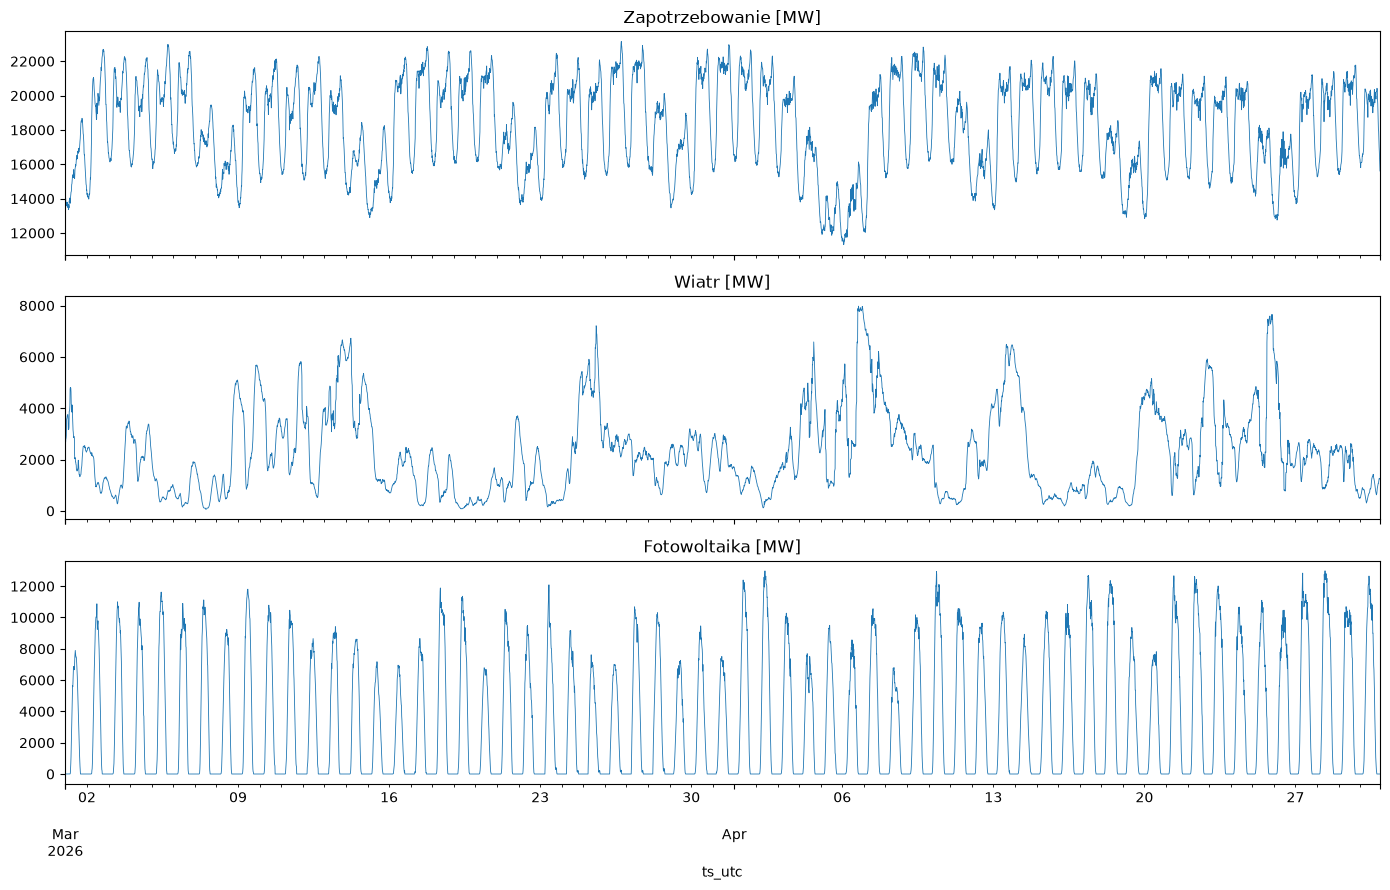

In [9]:
fig, os = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, kol, tytul in zip(os, kolumny, ["Zapotrzebowanie", "Wiatr", "Fotowoltaika"]):
    wykonanie[kol].plot(ax=ax, lw=0.6)
    ax.set_title(f"{tytul} [MW]")
plt.tight_layout()

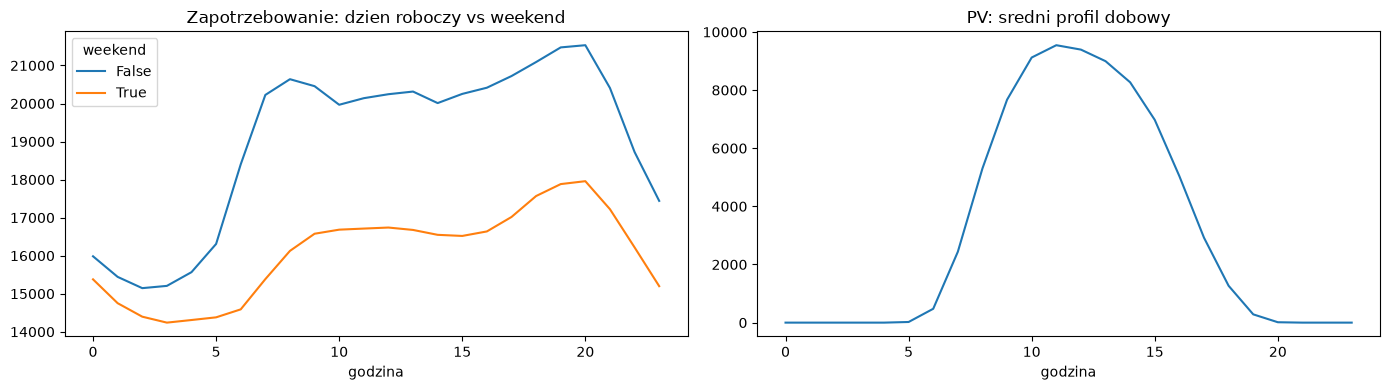

In [10]:
# Profil dobowy: srednia po godzinie lokalnej, osobno dni robocze i weekendy
profil = wykonanie.assign(
    godzina=wykonanie["ts_lokalny"].dt.hour,
    weekend=wykonanie["ts_lokalny"].dt.dayofweek >= 5,
)
fig, os = plt.subplots(1, 2, figsize=(14, 4))
profil.pivot_table(index="godzina", columns="weekend", values="demand").plot(ax=os[0])
os[0].set_title("Zapotrzebowanie: dzien roboczy vs weekend")
profil.pivot_table(index="godzina", values="pv").plot(ax=os[1], legend=False)
os[1].set_title("PV: sredni profil dobowy")
plt.tight_layout()

## 5. Prognozy PSE jako benchmark — kiedy zostaly opublikowane?

Chcemy porownac nasz model z prognoza PSE. Porownanie jest uczciwe tylko wtedy, gdy obie
prognozy powstaly **w tym samym momencie**, czyli dzien wczesniej. Sprawdzamy
`publication_ts` w planie dobowym (`pdgobpkd`).

In [11]:
plan = pobierz_pse("pdgobpkd", "2026-03-01", "2026-04-30")
plan["ts_utc"] = pd.to_datetime(plan["dtime_utc"]).dt.tz_localize("UTC")
plan["publikacja_utc"] = pd.to_datetime(plan["publication_ts_utc"]).dt.tz_localize("UTC")
plan["poczatek_doby_utc"] = (
    pd.to_datetime(plan["business_date"]).dt.tz_localize("Europe/Warsaw").dt.tz_convert("UTC")
)
plan["opoznienie_h"] = (plan["publikacja_utc"] - plan["poczatek_doby_utc"]).dt.total_seconds() / 3600

plan.groupby("business_date")["opoznienie_h"].first().describe()

count    61.000000
mean     23.103920
std       1.597487
min      21.794903
25%      22.497040
50%      22.588904
75%      22.948278
max      31.976671
Name: opoznienie_h, dtype: float64

**Kluczowe odkrycie:** plan "dobowy" ma `publication_ts` srednio **ok. 22,5 h po**
rozpoczeciu doby, ktorej dotyczy, czyli praktycznie na jej koniec. API trzyma tylko **ostatnia wersje** planu, a wczesniejsze
wersje sa nadpisywane.

Gdybysmy porownali nasz model z tymi liczbami, porownywalibysmy prognoze z dnia poprzedniego
z planem poprawionym juz w trakcie doby. To blad typu **look-ahead**: benchmark "widzial"
czesc przyszlosci.

**Wniosek dla pipeline:** od pierwszego dnia dzialania pipeline **archiwizujemy kazda
publikacje prognozy PSE** z momentem pobrania (tzw. *point-in-time snapshot*). Po kilku
tygodniach mamy uczciwy benchmark, ktorego nie da sie pobrac z API wstecz.
Takie rozwiazanie dobrze opisac w README, bo pokazuje dojrzalosc inzynierska.

Ponizej porownanie dla orientacji (z zastrzezeniem powyzej):

In [12]:
porownanie = plan.set_index("ts_utc")[["kse_pow_dem", "gen_wi", "gen_fv"]].join(
    wykonanie[["demand", "wi", "pv"]], how="inner"
)
for prog, fakt in [("kse_pow_dem", "demand"), ("gen_wi", "wi"), ("gen_fv", "pv")]:
    blad = (porownanie[prog] - porownanie[fakt]).abs()
    print(f"{fakt:>7}: MAE = {blad.mean():7.0f} MW   (srednia wartosc {porownanie[fakt].mean():7.0f} MW)")

 demand: MAE =     317 MW   (srednia wartosc   18190 MW)
     wi: MAE =     182 MW   (srednia wartosc    2262 MW)
     pv: MAE =     199 MW   (srednia wartosc    3241 MW)


Bledy wychodza podejrzanie male: ok. 1,7% dla zapotrzebowania i ok. 8% sredniej dla wiatru,
chociaz prognozowanie wiatru na dobe naprzod jest bardzo trudne. To potwierdza, ze te
liczby to plan poprawiany w trakcie doby, a nie prawdziwa prognoza z dnia poprzedniego.
Gdybysmy chcieli je "pobic", walczylibysmy z benchmarkiem, ktory zna czesc przyszlosci.

Dodatkowo trzeba sprawdzic w dokumentacji PSE, czy `kse_pow_dem` i `demand` maja te sama
definicje. **Otwarte pytanie do etapu 2.**

## 6. Pogoda — jakie dane wolno uzyc?

Open-Meteo ma dwa rodzaje danych historycznych:

- **archiwum (reanaliza ERA5)**: jaka pogoda *faktycznie byla*,
- **historical forecast**: jaka byla *prognoza* pogody w danym momencie.

Model prognozujacy na jutro bedzie mial do dyspozycji tylko **prognoze** pogody. Gdybysmy
trenowali go na faktycznej pogodzie, w testach wypadlby swietnie, a w produkcji duzo gorzej.
To jeden z najczestszych bledow w projektach prognostycznych (**data leakage**).

Pobieramy wiec *historical forecast* dla kilku punktow:

In [13]:
PUNKTY = {
    "Pomorze (wiatr)": (54.5, 17.0),
    "Wielkopolska (wiatr)": (52.4, 16.9),
    "Warszawa (popyt)": (52.23, 21.01),
    "Slask (popyt)": (50.26, 19.02),
    "Lubelskie (PV)": (51.25, 22.57),
}


def pobierz_pogode(nazwa: str, lat: float, lon: float, od: str, do: str) -> pd.DataFrame:
    odp = httpx.get(
        "https://historical-forecast-api.open-meteo.com/v1/forecast",
        params={
            "latitude": lat,
            "longitude": lon,
            "start_date": od,
            "end_date": do,
            "hourly": "temperature_2m,wind_speed_100m,shortwave_radiation,cloud_cover",
            "timezone": "UTC",
        },
        timeout=60,
    )
    odp.raise_for_status()
    df = pd.DataFrame(odp.json()["hourly"])
    df["ts_utc"] = pd.to_datetime(df.pop("time")).dt.tz_localize("UTC")
    df["punkt"] = nazwa
    return df


pogoda = pd.concat(
    [pobierz_pogode(n, lat, lon, "2026-03-01", "2026-04-30") for n, (lat, lon) in PUNKTY.items()]
)
pogoda.head()

,temperature_2m,wind_speed_100m,shortwave_radiation,cloud_cover,ts_utc,punkt
0,5.4,18.4,0.0,98,2026-03-01 00:00:00+00:00,Pomorze (wiatr)
1,5.6,18.9,0.0,93,2026-03-01 01:00:00+00:00,Pomorze (wiatr)
2,6.2,34.7,0.0,92,2026-03-01 02:00:00+00:00,Pomorze (wiatr)
3,7.1,42.0,0.0,100,2026-03-01 03:00:00+00:00,Pomorze (wiatr)
4,6.6,41.6,0.0,18,2026-03-01 04:00:00+00:00,Pomorze (wiatr)


Czy pogoda w ogole tlumaczy generacje? Wiatr na 100 m (srednia z punktow) vs generacja wiatrowa:

,wind_speed_100m,shortwave_radiation,temperature_2m
wi,0.81,-0.25,0.03
pv,-0.17,0.93,0.41
demand,-0.31,0.27,0.17


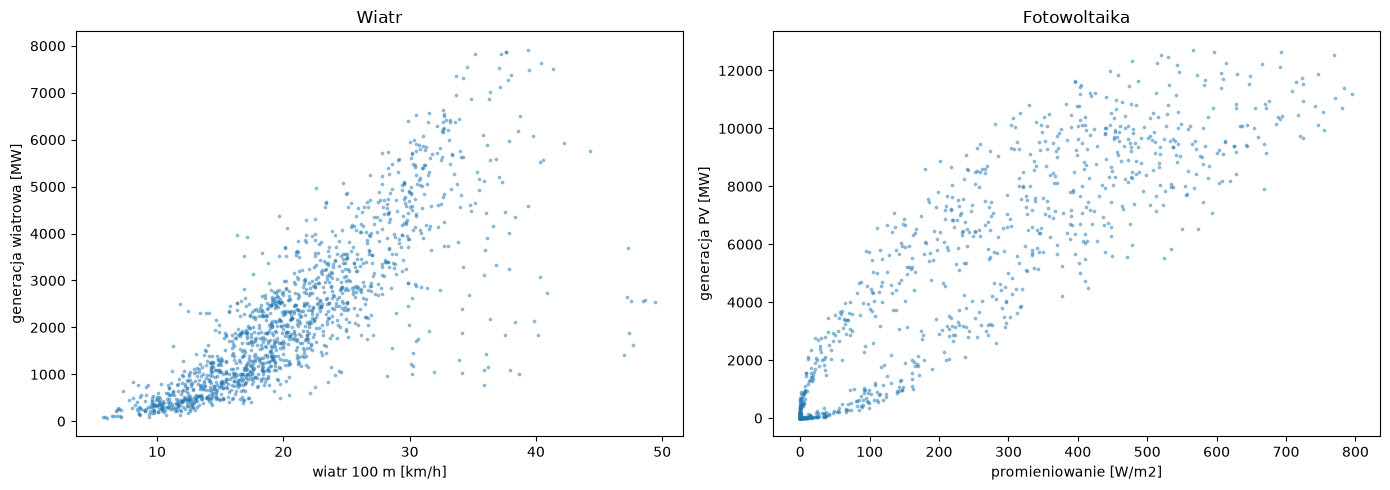

In [14]:
pogoda_srednia = pogoda.groupby("ts_utc")[["wind_speed_100m", "shortwave_radiation", "temperature_2m"]].mean()
godzinowo = wykonanie[kolumny].resample("1h").mean().join(pogoda_srednia, how="inner")

fig, os = plt.subplots(1, 2, figsize=(14, 5))
os[0].scatter(godzinowo["wind_speed_100m"], godzinowo["wi"], s=3, alpha=0.4)
os[0].set(xlabel="wiatr 100 m [km/h]", ylabel="generacja wiatrowa [MW]", title="Wiatr")
os[1].scatter(godzinowo["shortwave_radiation"], godzinowo["pv"], s=3, alpha=0.4)
os[1].set(xlabel="promieniowanie [W/m2]", ylabel="generacja PV [MW]", title="Fotowoltaika")
plt.tight_layout()

godzinowo.corr().loc[["wi", "pv", "demand"], ["wind_speed_100m", "shortwave_radiation", "temperature_2m"]].round(2)

Co widac:

- **Wiatr** (korelacja 0,81): ponizej ~10 km/h generacja jest bliska zera, potem rosnie
  szybciej niz liniowo. To fragment krzywej mocy turbiny. Przy duzych predkosciach
  (>35 km/h) czesc punktow **spada**: turbiny wylaczaja sie przy wichurach albo PSE
  ogranicza OZE. Zaleznosc jest nieliniowa, wiec model drzewiasty (LightGBM) poradzi
  sobie lepiej niz regresja liniowa.
- **PV** (korelacja 0,93): widac **dwie galezie**. Przy tym samym promieniowaniu generacja
  bywa wyraznie rozna. Podejrzenie: przesuniecie czasowe (Open-Meteo podaje srednia
  z *poprzedzajacej* godziny, a my usredniamy kwadranse inaczej) albo roznica rano/popoludnie.
  **Do zbadania w etapie 5.** Takie wykrycie i naprawienie bledu dobrze opisac w README.
- **Zapotrzebowanie**: wyrazny cykl dobowy i tygodniowy oraz dolek **5–6 kwietnia
  (Wielkanoc)**. Model bedzie potrzebowal kalendarza swiat.

## Wnioski dla architektury

1. **Klucz czasu = UTC.** Czas lokalny ma niejednoznaczne zapisy (`02a:15`) i doby
   o dlugosci 92/96/100 kwadransow.
2. **Paginacja**: 100 wierszy na strone, trzeba isc za `nextLink`.
3. **Prognozy PSE sa nadpisywane.** Trzeba archiwizowac kazda publikacje (snapshot),
   inaczej nie bedzie uczciwego benchmarku.
4. **Pogoda: tylko prognozy historyczne** (bez reanalizy), zeby uniknac wycieku danych.
5. **Rozdzielczosc**: PSE ma 15 minut, pogoda 1 godzine. Decyzja: modelujemy godzinowo
   (do rozwazenia w etapie 5).
6. **Swieta** wplywaja na popyt, wiec potrzebny jest kalendarz swiat jako cecha.
7. **Siec bywa zawodna** (w trakcie pisania tego notebooka API zerwalo polaczenie),
   wiec potrzebne sa retry i wznawianie pobierania.
8. **Otwarte**: definicje `kse_pow_dem` vs `demand`, korekty danych wykonawczych
   (czy `publication_ts` w `his-wlk-cal` sie zmienia?).

## Cwiczenia dla Ciebie

1. Pobierz `his-wlk-cal` dla calego roku 2025 i sprawdz, czy sa dni z brakujacymi
   kwadransami albo wartosciami `null`. Ktore kolumny maja najwiecej brakow?
2. Znajdz najwyzsza godzinowa generacje PV w danych. O ktorej godzinie i ktorego dnia byla?
3. *(trudniejsze)* Sprawdz, czy `his-wlk-cal` bywa korygowane: porownaj `publication_ts`
   z `business_date`. Jaki jest rozklad opoznien publikacji?